# 06 · Data checks and value at stake

1. Which tables agree with each other, and which don't?
2. A rough yearly value for each recommendation (FY26 base).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

lines = load_lines()
orders = load_orders()
fy26 = lines[lines["FY"] == 2026]
units_sold_26 = fy26["quantity"].sum()
cogs_26 = (fy26["net_line_EGP"] - fy26["margin_EGP"]).sum()

## 1. Data checks

In [2]:
# sales tables agree with each other
items_total = lines.groupby("sales_order_id")["net_line_EGP"].sum()
diff = (orders.set_index("sales_order_id")["net_before_tax_EGP"] - items_total).abs().max()
print("Max difference between order totals and their lines:", round(diff, 2))

# purchases vs sales
po = read("purchase_orders.csv", dates=["po_date"])
po_items = read("purchase_order_items.csv").merge(po, on="po_id")
po_units_26 = po_items[fiscal_year(po_items["po_date"]) == 2026]["quantity"].sum()

# transfers vs sales
tr = read("inventory_transfers.csv", dates=["transfer_date"])
tr_units_26 = read("inventory_transfer_items.csv").merge(tr, on="transfer_id").pipe(
    lambda d: d[fiscal_year(d["transfer_date"]) == 2026]["quantity_units"].sum())

# marketing claims vs real orders
claimed = read("marketing_campaigns.csv")["orders_attributed"].sum()

# payroll vs staff list
payroll = read("payroll.csv")
payroll_26 = payroll[fiscal_year(pd.to_datetime(payroll["pay_month"] + "-01")) == 2026]["net_paid_EGP"].sum()
implied = read("employees.csv")["salary_base_EGP_2026"].sum() * 12

# return flags vs return records
returns = read("sales_returns.csv")
flagged = orders[orders["status"] == "Partially returned"]
with_record = flagged["sales_order_id"].isin(returns["sales_order_id"]).sum()

# stock
stock = read("monthly_stock.csv")
stock_value = stock[stock["year_month"] == "2026-09"]["closing_stock_value_EGP"].sum()

checks = pd.Series({
    "Units bought vs units sold (FY26)": po_units_26 / units_sold_26,
    "Orders claimed by campaigns vs real orders": claimed / len(orders),
    "Orders flagged returned vs with a return record": len(flagged) / with_record,
    "Implied salaries vs payroll recorded (FY26)": implied / payroll_26,
    "Months of stock vs a 4-month norm": stock_value / (cogs_26 / 12) / 4,
    "Units transferred vs units sold (FY26)": tr_units_26 / units_sold_26,
}).sort_values()
checks.round(1)

Max difference between order totals and their lines: 0.0


Units transferred vs units sold (FY26)              2.4
Months of stock vs a 4-month norm                   6.4
Implied salaries vs payroll recorded (FY26)        16.3
Orders flagged returned vs with a return record    19.2
Orders claimed by campaigns vs real orders         44.6
Units bought vs units sold (FY26)                  67.6
dtype: float64

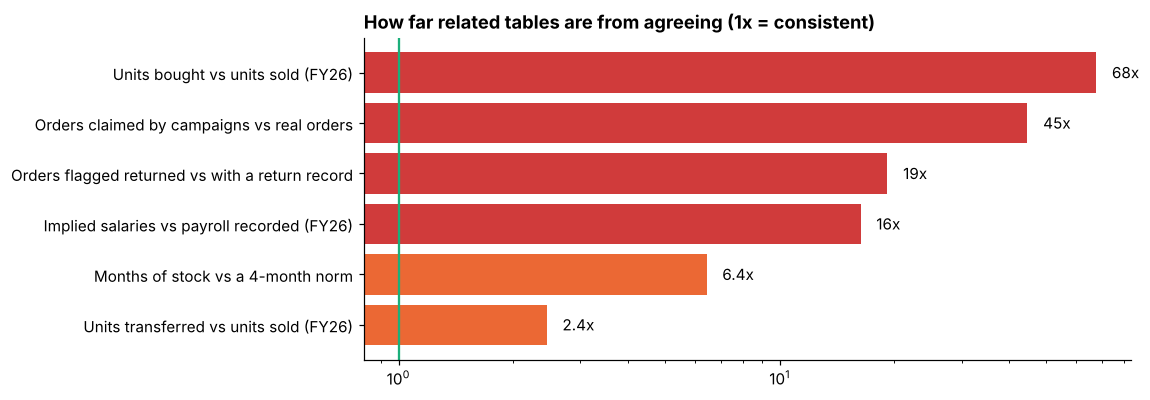

In [3]:
plt.figure(figsize=(9, 3.8))
plt.barh(checks.index, checks.values, color=[RED if v > 10 else ORANGE for v in checks])
plt.axvline(1, color=GREEN, lw=1.5)
plt.xscale("log")
for i, v in enumerate(checks.values):
    plt.text(v * 1.1, i, f"{v:.0f}x" if v >= 10 else f"{v:.1f}x", va="center")
plt.grid(False)
plt.title("How far related tables are from agreeing (1x = consistent)")
save("06_data_checks")
plt.show()

In [4]:
# things that are suspiciously even
cat_margin = lines.groupby("category_en").apply(lambda d: d["margin_EGP"].sum() / d["net_line_EGP"].sum())
print(f"Margin by category: {cat_margin.min():.1%} to {cat_margin.max():.1%}")
branch = orders.groupby("branch_id")["net_before_tax_EGP"].sum()
print(f"Branch sales: {branch.min() / branch.mean():.2f}x to {branch.max() / branch.mean():.2f}x the average")
print(returns["reason"].value_counts(normalize=True).round(3).to_dict())

Margin by category: 38.0% to 38.5%
Branch sales: 0.94x to 1.09x the average
{'Other': 0.203, 'Size issue': 0.202, 'Defect claim': 0.2, 'Exchange': 0.198, 'Wrong item': 0.198}


## 2. Value at stake (per year, FY26 base)

In [5]:
gm = fy26["margin_EGP"].sum() / fy26["net_line_EGP"].sum()

# stock: from ~26 months of cover to 12, carrying cost 15% a year
release = stock_value - 12 * cogs_26 / 12
stock_saving = 0.15 * release

# discounts capped at 5%
level = (fy26["discount_line_EGP"] / fy26["gross_line_EGP"]).round(2)
discount_saving = (fy26["discount_line_EGP"] - fy26["gross_line_EGP"] * np.minimum(level, 0.05)).sum()

# marketing: cut 25% of FY26 spend after testing
mk = read("marketing_campaigns.csv", dates=["start_date"])
marketing_saving = 0.25 * mk[fiscal_year(mk["start_date"]) == 2026]["spend_EGP"].sum()

# customers: average FY26 spend of an active customer
spend_active = orders[(orders["FY"] == 2026) & orders["customer_id"].notna()].groupby("customer_id")["net_before_tax_EGP"].sum().mean()
at_risk = 16_745          # from notebook 02
never_bought = 10_340     # from notebook 02
winback = 0.10 * at_risk * spend_active * gm
activation = 0.05 * never_bought * spend_active * gm

# transfers -30%, size-related refunds halved
transfer_saving = 0.30 * tr[fiscal_year(tr["transfer_date"]) == 2026]["transport_cost_EGP"].sum()
ret = read("sales_returns.csv", dates=["return_date"])
size_saving = 0.5 * ret[(fiscal_year(ret["return_date"]) == 2026) & (ret["reason"] == "Size issue")]["refund_amount_EGP"].sum()

value = pd.Series({
    "Lower stock cover (26 -> 12 months)": stock_saving,
    "Marketing: test, then cut 25%": marketing_saving,
    "Discount cap at 5%": discount_saving,
    "Win back 10% of At Risk": winback,
    "Fewer transfers (-30%)": transfer_saving,
    "Activate 5% of non-buyers": activation,
    "Halve size-related refunds": size_saving,
}).sort_values()

print("Cash released from stock:", millions(release))
print("Total per year:", millions(value.sum()))
value.map(millions)

Cash released from stock: 203.6M
Total per year: 48.6M


Halve size-related refunds              0.4M
Activate 5% of non-buyers               0.9M
Fewer transfers (-30%)                  1.0M
Win back 10% of At Risk                 2.9M
Discount cap at 5%                      5.6M
Marketing: test, then cut 25%           7.2M
Lower stock cover (26 -> 12 months)    30.5M
dtype: str

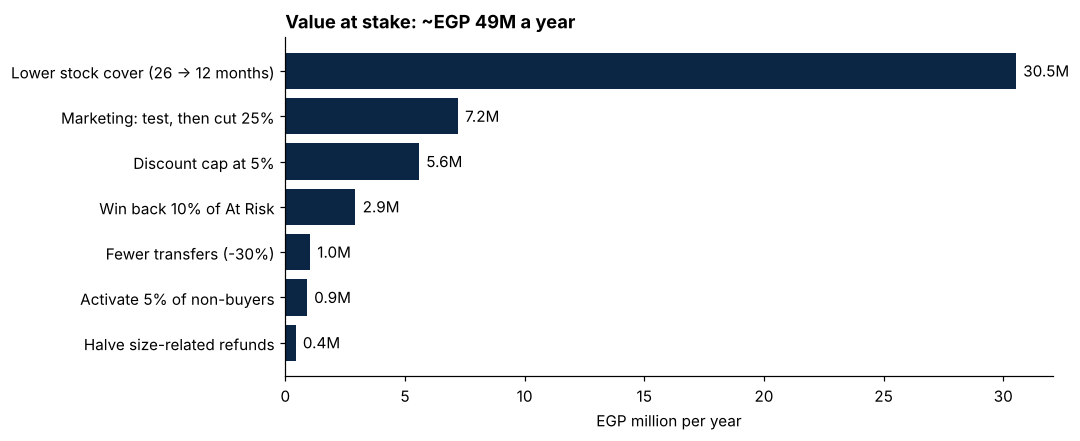

In [6]:
plt.figure(figsize=(9, 4))
plt.barh(value.index, value / 1e6, color=NAVY)
for i, v in enumerate(value / 1e6):
    plt.text(v + 0.3, i, f"{v:.1f}M", va="center")
plt.grid(False)
plt.xlabel("EGP million per year")
plt.title(f"Value at stake: ~EGP {value.sum() / 1e6:.0f}M a year")
save("06_value")
plt.show()

These are rough, conservative numbers. The biggest one (stock) depends on the stock table being right,
so the first real step is a physical stock count.